# **Detecção de Ocupação com Sensores IoT**
## Pipeline Preditivo aplicado à Automação Predial e Eficiência Energética na Indústria 4.0

**Projeto Avaliativo:** Integração de IA com Dados (SCTEC Aperfeiçoar)

**Aluna:** Anaysa Pereira Lopes

## Desafio

Um complexo industrial dotado de sensores ambientais IoT necessita saber, em tempo real, se suas salas técnicas e escritórios estão ocupados ou desocupados. Com essa informação, o ar-condicionado e a iluminação podem ser desligados automaticamente quando não há ninguém presente, diminuindo o consumo de energia.

A finalidade deste projeto é criar um modelo capaz de realizar essa previsão com base na leitura dos sensores.

A base usada é a [Occupancy Detection Dataset](https://archive.ics.uci.edu/dataset/357/occupancy+detection) (UCI Machine Learning Repository), com as seguintes variáveis:

* Temperature: temperatura do ambiente (°C)
* Humidity: umidade relativa do ar (%)
* Light: luminosidade (Lux)
* CO2: concentração de dióxido de carbono (ppm)
* HumidityRatio: razão de umidade, calculada a partir da temperatura e da umidade
* Occupancy: variável alvo (0 = desocupado, 1 = ocupado)

In [1]:
# Bibliotecas

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Configurações visuais dos gráficos
sns.set_theme(style="whitegrid", palette="pastel")
plt.rcParams["figure.figsize"] = (10, 5)

## Base de Dados

A base foi fornecida junto com o enunciado do projeto e fica na pasta `data/`. Usei caminho relativo na leitura para que o notebook funcione em qualquer computador.

In [2]:
# Carregamento dos dados

df = pd.read_csv("data/occupancy_completo.csv")
df.head()

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-04 17:51:00,23.18,27.272,426.0,721.25,47.929.881.765.052,1
1,2015-02-04 17:51:59,23.15,272.675,429.5,714.0,47.834.409.493.106,1
2,2015-02-04 17:53:00,23.15,27.245,426.0,713.5,47.794.635.244.219,1
3,2015-02-04 17:54:00,23.15,27.2,426.0,708.25,47.715.088.260.817,1
4,2015-02-04 17:55:00,23.1,27.2,426.0,704.5,47.569.929.333.151,1


## 1. Análise Exploratória (EDA)

In [3]:
# Quantidade de linhas e colunas
df.shape

(20560, 7)

In [4]:
# Tipo de cada coluna e valores preenchidos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20560 entries, 0 to 20559
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   date           20560 non-null  object
 1   Temperature    20560 non-null  object
 2   Humidity       20560 non-null  object
 3   Light          20560 non-null  object
 4   CO2            20560 non-null  object
 5   HumidityRatio  20560 non-null  object
 6   Occupancy      20560 non-null  int64 
dtypes: int64(1), object(6)
memory usage: 1.1+ MB


In [5]:
# Amostra aleatória
df.sample(20, random_state=42)

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
17775,2015-02-16 10:54:59,21.5,27.84,454.0,1019.5,44.147.635.011.136,1
5971,2015-02-08 21:22:00,19.5,27.525,0.0,451.0,38.546.013.122.196,0
11804,2015-02-12 07:24:00,20.5,22.445,0.0,734.5,33.413.159.812.628,0
18114,2015-02-16 16:34:00,21.79,29.79,429.0,934.5,48.115.727.479.697,1
290,2015-02-04 22:40:59,21.29,25.7,0.0,475.5,40.207.687.259.132,0
1747,2015-02-05 22:58:00,20.5,21.2,0.0,449.0,3.155.036.663.195,0
20291,2015-02-18 04:51:00,20.79,26.1,0.0,1517.5,39.594.088.253.607,0
14032,2015-02-13 20:31:59,20.5,31.5,0.0,514.5,46.994.897.838.997,0
8271,2015-02-02 16:27:00,22.772,26.934,438.0,993.2,46.167.934.930.926,1
5905,2015-02-08 20:16:00,19.39,27.5,0.0,443.0,38.246.535.340.678,0


### 1.1 Ajuste de formato

Como alguns valores dos sensores apresentavam o ponto decimal deslocado (por exemplo, `272.675` em vez de `27.2675`), as colunas foram interpretadas como texto. Para corrigir, retirei os pontos e ajustei a posição do decimal de acordo com a faixa de valores de cada sensor.

In [6]:
# Correção de Temperature e Humidity
for coluna in ["Temperature", "Humidity"]:
    digitos = df[coluna].str.replace(".", "", regex=False)
    df[coluna] = (digitos.str[:2] + "." + digitos.str[2:]).astype(float)

df[["Temperature", "Humidity"]].describe()

,Temperature,Humidity
count,20560.000000,20560.000000
mean,20.906212,27.655925
std,1.055315,4.982154
min,19.000000,16.745000
25%,20.200000,24.500000
50%,20.700000,27.290000
75%,21.525000,31.290000
max,24.408333,39.500000


In [7]:
# Correção de HumidityRatio
digitos = df["HumidityRatio"].str.replace(".", "", regex=False)
df["HumidityRatio"] = ("0.00" + digitos).astype(float)

df["HumidityRatio"].describe()

count    20560.000000
mean         0.004228
std          0.000768
min          0.002674
25%          0.003719
50%          0.004292
75%          0.004832
max          0.006476
Name: HumidityRatio, dtype: float64

No CO2, só existe uma posição possível para o decimal dentro da faixa da base (412 a 2.076 ppm), então os valores foram corrigidos. Na Light, mais de uma posição é possível, então os valores incorretos foram transformados em NaN e serão tratados na etapa de limpeza.

In [8]:
# Correção de CO2
def corrigir_co2(valor):
    if valor.count(".") <= 1:
        return float(valor)
    digitos = valor.replace(".", "")
    if int(digitos[:3]) >= 412:
        return float(digitos[:3] + "." + digitos[3:])
    return float(digitos[:4] + "." + digitos[4:])

df["CO2"] = df["CO2"].apply(corrigir_co2)
df["CO2"].describe()

count    20560.000000
mean       690.553276
std        311.201281
min        412.750000
25%        460.000000
50%        565.416667
75%        804.666667
max       2076.500000
Name: CO2, dtype: float64

In [9]:
# Conversão de Light
df["Light"] = pd.to_numeric(df["Light"], errors="coerce")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20560 entries, 0 to 20559
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           20560 non-null  object 
 1   Temperature    20560 non-null  float64
 2   Humidity       20560 non-null  float64
 3   Light          19874 non-null  float64
 4   CO2            20560 non-null  float64
 5   HumidityRatio  20560 non-null  float64
 6   Occupancy      20560 non-null  int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 1.1+ MB


A coluna `date` está no formato de texto e simplesmente armazena o instante de cada medição. Como o objetivo é identificar a ocupação por meio das leituras dos sensores, essa coluna foi eliminada.

In [10]:
# Remoção da coluna date
df = df.drop(columns=["date"])
df.head()

,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,23.18,27.2720,426.0,721.25,0.004793,1
1,23.15,27.2675,429.5,714.00,0.004783,1
2,23.15,27.2450,426.0,713.50,0.004779,1
3,23.15,27.2000,426.0,708.25,0.004772,1
4,23.10,27.2000,426.0,704.50,0.004757,1


### 1.2 Resumo estatístico e gráficos

In [ ]:
# Resumo estatístico
df.describe()

In [ ]:
# Proporção das classes de Occupancy
ax = sns.countplot(data=df, x="Occupancy", hue="Occupancy", legend=False)
ax.set_title("Distribuição da variável alvo")
ax.set_xlabel("Occupancy (0 = desocupado, 1 = ocupado)")
ax.set_ylabel("Quantidade de registros")
plt.show()

df["Occupancy"].value_counts(normalize=True)

In [ ]:
# Distribuição das variáveis preditoras
preditoras = ["Temperature", "Humidity", "Light", "CO2", "HumidityRatio"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, coluna in zip(axes.flat, preditoras):
    sns.histplot(data=df, x=coluna, hue="Occupancy", bins=30, ax=ax)
    ax.set_title(coluna)

axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Correlação de Pearson entre as variáveis
cores = sns.color_palette("deep")
paleta_calor = sns.blend_palette([cores[0], "white", cores[1]], as_cmap=True)

plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(method="pearson"), annot=True, fmt=".2f", cmap=paleta_calor, vmin=-1, vmax=1)
plt.title("Correlação de Pearson entre as variáveis")
plt.show()

In [ ]:
# Relação entre luminosidade, CO2 e ocupação
ax = sns.scatterplot(data=df, x="Light", y="CO2", hue="Occupancy", alpha=0.6, s=15)
ax.set_title("Relação entre luminosidade, CO2 e ocupação")
plt.show()

In [ ]:
# Redundância entre Humidity e HumidityRatio
ax = sns.scatterplot(data=df, x="Humidity", y="HumidityRatio", alpha=0.6, s=15)
ax.set_title("Humidity x HumidityRatio")
plt.show()

### 1.3 Análise exploratória

O conjunto de dados conta com 20.560 registros, sendo que a sala aparece ocupada em apenas 23% das amostras. Devido a esse desbalanceamento entre as classes, a separação entre treino e teste deve utilizar estratificação (`stratify`) para preservar a mesma proporção em ambos os subconjuntos.

Na matriz de correlação, `Light` apresenta associação muito forte com a ocupação (0,92): permanece próxima de zero quando o ambiente está vazio e sobe para cerca de 400 a 500 lux quando há pessoas. `Temperature` (0,56) e `CO2` (0,50) exibem correlação moderada. O nível de CO2 aumenta com a presença de pessoas, mas cai lentamente; no gráfico de dispersão, isso se reflete em observações com iluminação apagada e concentrações residuais de CO2 ainda elevadas. Já `Humidity` (0,05) e `HumidityRatio` (0,26) têm correlação fraca com a variável alvo.

Entre si, `Humidity` e `HumidityRatio` registram correlação de 0,93, sinalizando redundância que pode distorcer o cálculo de distâncias no KNN. A `HumidityRatio` captura melhor a relação com a ocupação por expressar a massa real de vapor d'água no ar, mas optei por manter as duas nesta etapa.

As variáveis também operam em escalas bastante distintas: a `HumidityRatio` varia na ordem de milésimos, enquanto `Light` e `CO2` alcançam valores na casa dos milhares. Essa diferença não impacta modelos baseados em árvores, como a Árvore de Decisão, mas afeta algoritmos baseados em distância, como o KNN. Por isso, o pipeline do KNN aplicará `StandardScaler` antes do treinamento.


## 2. Limpeza e Tratamento de Dados

In [11]:
# Linhas duplicadas
df.duplicated().sum()

np.int64(1443)

Identificaram-se 1.443 linhas duplicadas. Elas apareceram após a exclusão da coluna `date`: em períodos em que o ambiente não sofre alterações, os sensores captam os mesmos valores consecutivamente por minutos. Escolhi excluí-las para impedir que registros iguais apareçam simultaneamente no treinamento e no teste, o que aumentaria artificialmente a acurácia.

In [12]:
# Remoção das linhas duplicadas
df = df.drop_duplicates()
df.shape

(19117, 6)

In [13]:
# Valores ausentes por coluna
df.isna().sum()

Temperature        0
Humidity           0
Light            682
CO2                0
HumidityRatio      0
Occupancy          0
dtype: int64

In [14]:
# Média e mediana da Light
df["Light"].agg(["mean", "median"])

mean      133.643488
median      0.000000
Name: Light, dtype: float64

A média (133,6) está bem afastada da mediana (0), o que reforça a significativa assimetria da `Light` vista no histograma: a maioria dos registros indica luz apagada, enquanto uma minoria apresenta valores elevados. Como a média é influenciada por valores extremos, escolhi usar a mediana para preencher os 682 valores faltantes.

Como a mediana é 0, esses registros são considerados como luz apagada, mesmo que a sala estivesse ocupada. Como constituem apenas 3,6% da base, o efeito previsto nos modelos é reduzido.

In [15]:
# Imputação pela mediana
df["Light"] = df["Light"].fillna(df["Light"].median())
df.isna().sum()

Temperature      0
Humidity         0
Light            0
CO2              0
HumidityRatio    0
Occupancy        0
dtype: int64

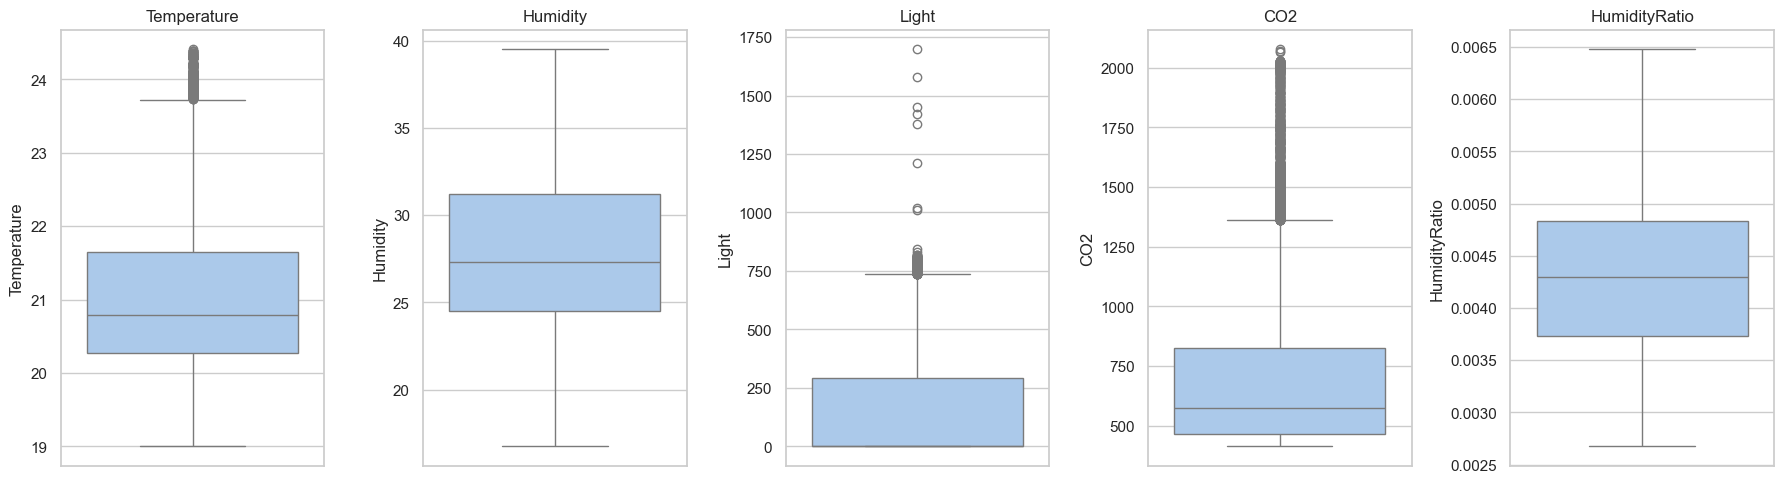

In [16]:
# Boxplots das variáveis explicativas
preditoras = ["Temperature", "Humidity", "Light", "CO2", "HumidityRatio"]

fig, axes = plt.subplots(1, 5, figsize=(18, 5))
for ax, coluna in zip(axes, preditoras):
    sns.boxplot(data=df, y=coluna, ax=ax)
    ax.set_title(coluna)

plt.tight_layout()
plt.show()

Os boxplots mostram valores superiores às hastes para `Temperature`, `Light` e `CO2`, ao passo que `Humidity` e `HumidityRatio` não exibem outliers. Esses valores podem ser alcançados fisicamente em um ambiente de escritório (como quando há iluminação natural intensa ou muitas pessoas no local) e, no caso da `Light`, geralmente correspondem a períodos de ocupação. Decidi mantê-los porque refletem situações reais, não erros de medição.